# USGS daily mean streamflow at a gauge

Inspect USGS daily mean discharge (parameter `00060`, statistic `00003`) at monitoring location `USGS-01491000` for 2020–2021. This is flow through a gauge cross-section, **not** asset inundation depth or a design-flood curve. Daily mean flow is not an instantaneous annual peak. Observation dates and source units are retained, as are approval status, qualifiers and time-series identity.

USGS data may be revised, including approved observations. Pages are fetched sequentially without a transactional upstream snapshot. Save the cache and checksum to reproduce the captured observations; this checksum covers the canonicalized feature records rather than raw HTTP response bytes. Data source: [USGS Water Data for the Nation](https://doi.org/10.5066/F7P55KJN); see [citation guidance](https://waterdata.usgs.gov/citation/) and [data status](https://water.usgs.gov/data/disclaimer.html). The [companion pipeline](../../pipelines/usgs_streamflow_pipeline.py) streams records into Parquet.

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.usgs_streamflow_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "usgs_streamflow"
source = run(output)
print("Pages:", source["pages"], "observations:", source["observations"])
print("Snapshot SHA-256:", source["sha256"])
print("Retrieved:", source["retrieved_at"])

Pages: 2 observations: 731
Snapshot SHA-256: 0fef36ec8a9fad5d2a480d9e65dc5c3218e78b2bd64c701e69ddeeee0741880b
Retrieved: 2026-10-30T19:07:56.500007+00:00


In [2]:
# This small, bounded example is loaded for inspection; the pipeline streams batches.
daily = pq.read_table(output / "daily.parquet").to_pandas()
print("Units:", daily["unit"].dropna().unique())
print("Status counts:", daily["approval_status"].value_counts(dropna=False).to_dict())
print("Time series:", daily["time_series_id"].nunique())
daily.sort_values("date")[["date", "flow", "unit", "approval_status", "qualifier_json"]].head()

Units: <ArrowStringArray>
['ft^3/s']
Length: 1, dtype: str
Status counts: {'Approved': 731}
Time series: 1


,date,flow,unit,approval_status,qualifier_json
578,2020-01-01,113.0,ft^3/s,Approved,null
551,2020-01-02,96.4,ft^3/s,Approved,null
123,2020-01-03,94.2,ft^3/s,Approved,null
363,2020-01-04,107.0,ft^3/s,Approved,null
619,2020-01-05,133.0,ft^3/s,Approved,null


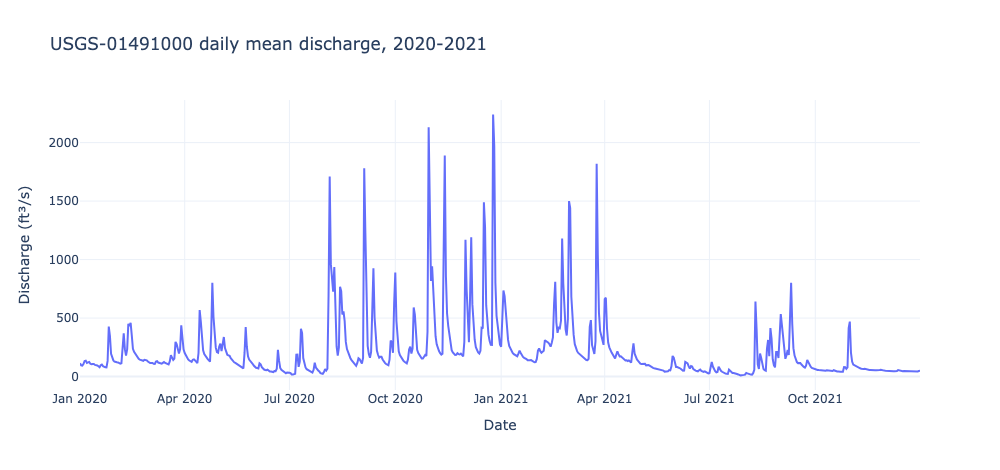

In [3]:
# Daily mean discharge for the gauge; missing values stay gaps.
view = daily.sort_values("date")
fig = go.Figure(go.Scatter(x=view["date"], y=view["flow"], mode="lines", connectgaps=False))
fig.update_layout(title="USGS-01491000 daily mean discharge, 2020-2021",
                  xaxis_title="Date", yaxis_title="Discharge (ft³/s)")
fig.show()


In [4]:
# Distinguish missing calendar days and null values within each reported series.
expected_days = 731
for series, group in daily.groupby("time_series_id", dropna=False):
    print("Series:", series)
    print("Unique dates:", group["date"].nunique(), "of", expected_days)
    print("Null flows:", group["flow"].isna().sum())
    print("Duplicate dates:", group["date"].duplicated().sum())

Series: 847d8581ff6c45f58ff7cb90dec31fab
Unique dates: 731 of 731
Null flows: 0
Duplicate dates: 0


A complete daily record alone does not establish flood risk or support an extreme-value model. Review station metadata, missingness, qualifiers, changing measurement practices and the applicable hydrologic method before any downstream inference. Do not merge separate time series without understanding their support.